# CRISP-DM Phase 5 – Evaluation

**Goal:** check the selected model against the success criteria of Phase 1 on data it has never seen, and verify **why** it
decides what it decides (SHAP).

Previous phase: `04_modeling.ipynb` · Next phase: `06_deployment.ipynb`

In [1]:
import sys
sys.path.insert(0, "..")  # project root, to import the src package

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

import shap
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

from src.explain import shap_values
from src.preprocessing import CLASS_LABELS, CLASSES, FEATURE_LABELS
from src.sinan import TRAIN_YEAR, load_dataset
from src.train import SEED, build_models, compute_metrics

info = json.loads(open("../models/metrics.json", encoding="utf-8").read())
X, y, _ = load_dataset(TRAIN_YEAR)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
model = build_models()[info["model_name"]].fit(X_train, y_train)
proba = model.predict_proba(X_test)
print("Model:", info["model_name"], "| dengue alert threshold:", info["dengue_threshold"])

Model: LightGBM | dengue alert threshold: 0.34


## 5.1 Test set (20 %, never seen)

In [2]:
m = compute_metrics(y_test, proba, info["dengue_threshold"])
print(f"macro ROC-AUC {m['roc_auc']:.3f} | balanced accuracy {m['balanced_accuracy']:.3f} (chance 0.333)")
pd.DataFrame(m["per_class"]).set_index("label")[["recall", "precision", "f1", "roc_auc", "support"]]

macro ROC-AUC 0.858 | balanced accuracy 0.688 (chance 0.333)


,recall,precision,f1,roc_auc,support
label,,,,,
Dengue,0.802,0.707,0.752,0.898,8000
Chikungunya,0.721,0.677,0.698,0.866,8000
Other febrile illness,0.541,0.676,0.601,0.810,8000


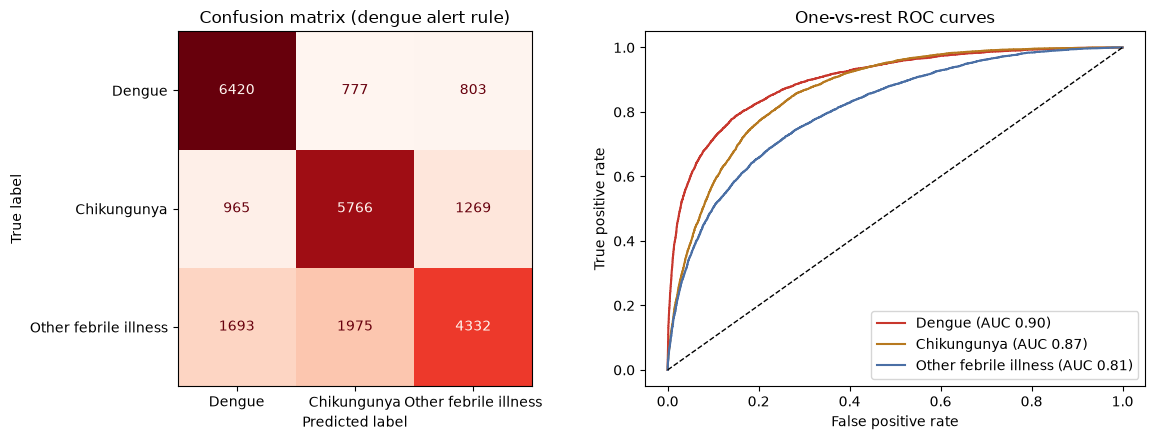

In [3]:
labels = [CLASS_LABELS[c] for c in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(np.array(m["confusion_matrix"]), display_labels=labels).plot(ax=axes[0], cmap="Reds", colorbar=False)
axes[0].set_title("Confusion matrix (dengue alert rule)")
for i, (c, color) in enumerate(zip(CLASSES, ["#c8372d", "#b7791f", "#4a6fa5"])):
    fpr, tpr, _ = roc_curve(y_test == i, proba[:, i])
    axes[1].plot(fpr, tpr, color=color, label=f"{CLASS_LABELS[c]} (AUC {roc_auc_score(y_test == i, proba[:, i]):.2f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("One-vs-rest ROC curves")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5.2 Explainability with SHAP

SHAP splits each prediction into one contribution per feature (Lundberg & Lee, 2017). For tree models the exact values are
computed with TreeSHAP. Positive = pushes toward the class; negative = away from it.

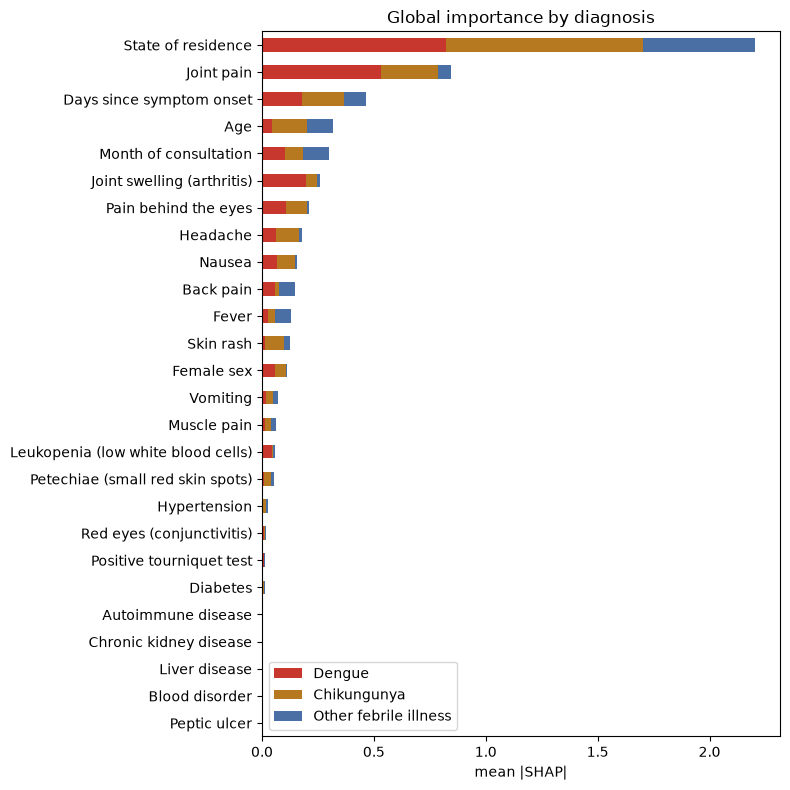

In [4]:
sample = X_test.sample(2000, random_state=SEED)
values = shap_values(model, sample)  # (rows, features, classes)
names = [FEATURE_LABELS[c] for c in sample.columns]
importance = pd.DataFrame(np.abs(values).mean(axis=0), index=names, columns=labels)
ax = importance.loc[importance.sum(axis=1).sort_values().index].plot.barh(
    stacked=True, figsize=(8, 8), color=["#c8372d", "#b7791f", "#4a6fa5"])
ax.set_xlabel("mean |SHAP|"); ax.set_title("Global importance by diagnosis"); plt.tight_layout(); plt.show()

--- Dengue: each dot is a patient; red = high feature value (e.g. symptom present)


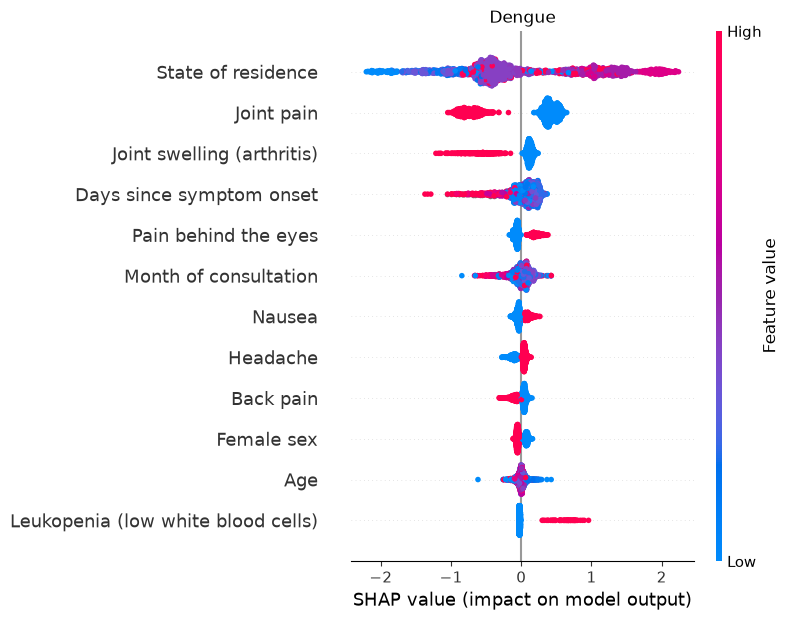

--- Chikungunya: each dot is a patient; red = high feature value (e.g. symptom present)


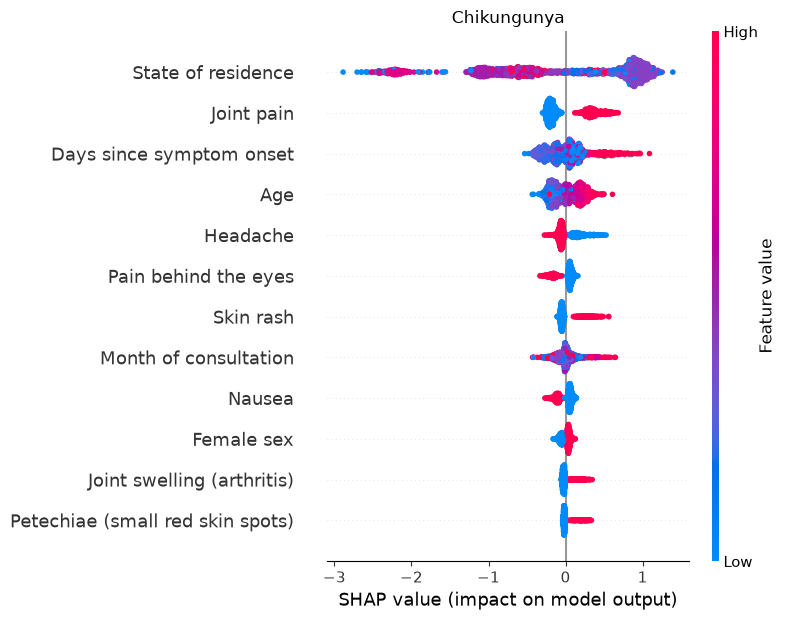

In [5]:
for i, c in enumerate(CLASSES[:2]):
    print(f"--- {CLASS_LABELS[c]}: each dot is a patient; red = high feature value (e.g. symptom present)")
    shap.summary_plot(values[:, :, i], sample.values, feature_names=names, max_display=12, show=False)
    plt.title(CLASS_LABELS[c]); plt.tight_layout(); plt.show()

**Reading:** the model's reasoning should match clinical knowledge — joint pain and arthritis push toward chikungunya;
leukopenia, retro-orbital pain and headache toward dengue. If an implausible feature dominated, it would point to a data
problem (leakage or bias). This check is as important as the metrics.

## 5.3 One patient: why this suggestion?

Actual: Chikungunya | probabilities: {'Dengue': np.float64(0.192), 'Chikungunya': np.float64(0.593), 'Other febrile illness': np.float64(0.216)}


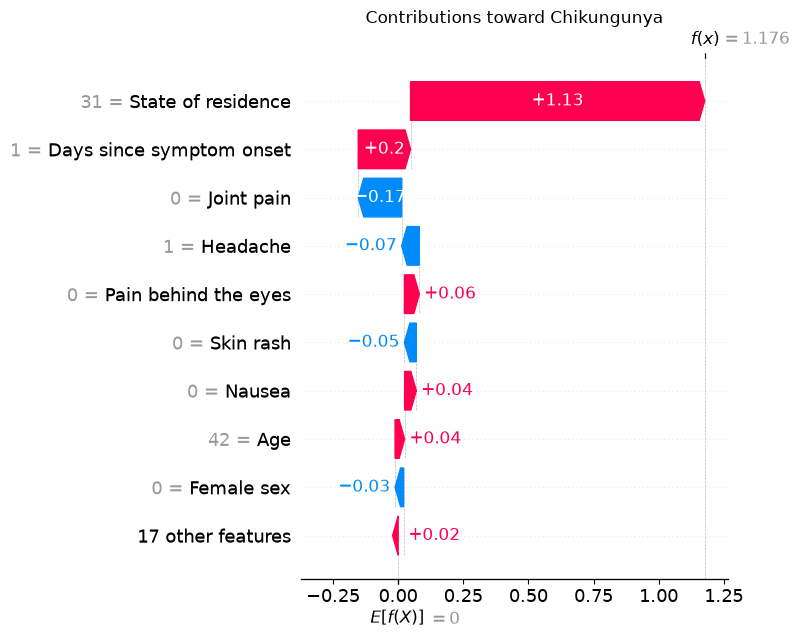

In [6]:
row = X_test.iloc[[0]]
p = model.predict_proba(row)[0]
k = int(p.argmax())
print("Actual:", CLASS_LABELS[CLASSES[y_test.iloc[0]]], "| probabilities:", dict(zip(labels, p.round(3))))
explanation = shap.Explanation(values=shap_values(model, row)[0, :, k], data=row.values[0], feature_names=names,
                               base_values=0.0)
shap.plots.waterfall(explanation, max_display=10, show=False); plt.title(f"Contributions toward {labels[k]}")
plt.tight_layout(); plt.show()

## 5.4 Robustness: temporal and external validation

Computed by `python -m src.train` and stored in `models/metrics.json`:
- **Temporal:** the model trained on 2023 is evaluated on a balanced 2025 sample.
- **External (Colombia):** P(dengue) on SIVIGILA Tuluá, dengue confirmed vs discarded. The Colombian form records only 7 of
  the model's symptoms; the rest are "not reported".

In [7]:
tv, ev = info["temporal_validation"], info["external_validation"]
print(f"{tv['scenario']}: macro ROC-AUC {tv['roc_auc']:.3f}, balanced accuracy {tv['balanced_accuracy']:.3f}")
display(pd.DataFrame(tv["per_class"]).set_index("label")[["recall", "roc_auc"]])
if ev:
    print(f"Colombia (Tuluá, n={ev['n']:,}): dengue ROC-AUC {ev['roc_auc_dengue']:.3f}, "
          f"dengue recall {ev['dengue_recall']:.3f}, specificity {ev['specificity']:.3f}")

Train 2023, evaluate 2025: macro ROC-AUC 0.760, balanced accuracy 0.542


,recall,roc_auc
label,,
Dengue,0.866,0.810
Chikungunya,0.212,0.708
Other febrile illness,0.550,0.763


Colombia (Tuluá, n=19,340): dengue ROC-AUC 0.562, dengue recall 0.452, specificity 0.615


## 5.5 Review against the success criteria

In [8]:
best = next(r for r in info["cv_metrics"] if r["model"] == info["model_name"])
baseline = next(r for r in info["cv_metrics"] if r["model"] == "Logistic Regression")
t = info["test_metrics"]
rows = [
    ("Dengue recall >= 0.80 (test)", t["per_class"][0]["recall"], t["per_class"][0]["recall"] >= 0.80),
    ("Macro ROC-AUC >= 0.80 (test)", t["roc_auc"], t["roc_auc"] >= 0.80),
    ("Better than the linear baseline (CV ROC-AUC)", best["roc_auc"] - baseline["roc_auc"], best["roc_auc"] > baseline["roc_auc"]),
    ("Holds in 2025 (macro ROC-AUC >= 0.70)", tv["roc_auc"], tv["roc_auc"] >= 0.70),
]
if ev:
    rows.append(("Transfers to Colombia (dengue ROC-AUC >= 0.70)", ev["roc_auc_dengue"], ev["roc_auc_dengue"] >= 0.70))
pd.DataFrame(rows, columns=["criterion", "value", "met"])

,criterion,value,met
0,Dengue recall >= 0.80 (test),0.802,True
1,Macro ROC-AUC >= 0.80 (test),0.858,True
2,Better than the linear baseline (CV ROC-AUC),0.156,True
3,Holds in 2025 (macro ROC-AUC >= 0.70),0.760,True
4,Transfers to Colombia (dengue ROC-AUC >= 0.70),0.562,False


## 5.6 Conclusions and decision

1. With clinical findings **and** epidemiological context the model passes the 0.80 target; its SHAP explanations match
   clinical knowledge and local circulation.
2. Arboviruses share most symptoms: with clinical findings alone the ceiling was ~0.71. Most of the gain comes from
   **where and when** the patient consults. This is legitimate pre-test probability, but part of the state effect may
   reflect each state's laboratory practices, and it ties the model to Brazil.
3. The dengue alert keeps dengue recall at the target, at the cost of more patients flagged as dengue.
4. It holds in a later year (2025), but **not in Colombia**: on Tuluá data the dengue ROC-AUC is close to chance. The
   Colombian form lacks most of the model's findings, there is no Brazilian state, and the population differs, so the
   model must be retrained with local data (Colombian departments as context) before any real use in Colombia.

**Decision:** deploy as a **decision-support** tool with the dengue alert and a SHAP explanation on every result.
**Next CRISP-DM iteration:** numeric lab values (platelets, white cells, hematocrit) from hospital records and retraining
with Colombian data.